In [3]:
#1. Imports and File Paths

from pathlib import Path
import pandas as pd
from IPython.display import display

filename = "credit_card_transactions_clean.csv"

# Check common locations relative to Jupyter's current folder and your Windows folders.
candidates = [
    Path("etl_output") / filename,
    Path("output") / filename,
    Path.home() / "Downloads" / filename,
    Path.home() / "credit_card_project" / "etl_output" / filename,
    Path.home() / "credit_card_project" / "output" / filename,
]

DATA_PATH = next((p for p in candidates if p.exists()), None)

# If it wasn't in those folders, open a window so you can select it.
if DATA_PATH is None:
    import tkinter as tk
    from tkinter import filedialog

    root = tk.Tk()
    root.withdraw()
    selected_file = filedialog.askopenfilename(
        title="Select credit_card_transactions_clean.csv",
        filetypes=[("CSV files", "*.csv")]
    )
    root.destroy()

    if selected_file:
        DATA_PATH = Path(selected_file)

if DATA_PATH is None or not DATA_PATH.exists():
    raise FileNotFoundError(
        "Clean CSV not found. Run the ETL walkthrough first, then select "
        "credit_card_transactions_clean.csv from its output folder."
    )

df = pd.read_csv(DATA_PATH)
print(f"Loaded: {DATA_PATH}")
print(f"Rows: {len(df):,} | Columns: {len(df.columns)}")
display(df.head())

Loaded: C:\Users\jpmee\Downloads\credit_card_transactions_clean.csv
Rows: 1,296,675 | Columns: 19


,transaction_id,transaction_datetime,merchant,category,amount,gender,city,state,zip_code,customer_latitude,customer_longitude,city_population,job,customer_age,transaction_unix_time,merchant_latitude,merchant_longitude,merchant_zip_code,is_fraud
0,0b242abb623afc578575680df30655b9,2019-01-01 00:00:18,"fraud_Rippin, Kub and Mann",misc_net,4.97,f,Moravian Falls,NC,28654,36.0788,-81.1781,3495,"Psychologist, counselling",30,1325376018,36.011293,-82.048315,28705.0,0
1,1f76529f8574734946361c461b024d99,2019-01-01 00:00:44,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,f,Orient,WA,99160,48.8878,-118.2105,149,Special educational needs teacher,40,1325376044,49.159047,-118.186462,NaN,0
2,a1a22d70485983eac12b5b88dad1cf95,2019-01-01 00:00:51,fraud_Lind-Buckridge,entertainment,220.11,m,Malad City,ID,83252,42.1808,-112.2620,4154,Nature conservation officer,56,1325376051,43.150704,-112.154481,83236.0,0
3,6b849c168bdad6f867558c3793159a81,2019-01-01 00:01:16,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,m,Boulder,MT,59632,46.2306,-112.1138,1939,Patent attorney,51,1325376076,47.034331,-112.561071,NaN,0
4,a41d7549acf90789359a9aa5346dcb46,2019-01-01 00:03:06,fraud_Keeling-Crist,misc_pos,41.96,m,Doe Hill,VA,24433,38.4207,-79.4629,99,Dance movement psychotherapist,32,1325376186,38.674999,-78.632459,22844.0,0


In [3]:
# 2. Stream and Aggregate the Data

from pathlib import Path
import pandas as pd

DATA_PATH = Path.home() / "Downloads" / "credit_card_transactions_clean.csv"

if not DATA_PATH.exists():
    import tkinter as tk
    from tkinter import filedialog

    root = tk.Tk()
    root.withdraw()
    selected_file = filedialog.askopenfilename(
        title="Select credit_card_transactions_clean.csv",
        filetypes=[("CSV files", "*.csv")]
    )
    root.destroy()

    if not selected_file:
        raise FileNotFoundError("Select the downloaded clean CSV to continue.")

    DATA_PATH = Path(selected_file)

print(f"Using: {DATA_PATH}")

Using: C:\Users\jpmee\Downloads\credit_card_transactions_clean.csv


In [8]:
#3. Overall Metrics and Data Quality 


# STEP 3: OVERALL METRICS AND DATA QUALITY
# Using Pandas and PyArrow

import pandas as pd
import pyarrow as pa
import pyarrow.csv as pv
from pathlib import Path
from IPython.display import display

print("STEP 3: OVERALL METRICS AND DATA QUALITY")
print("=" * 55)

# 1. Locate the credit card transactions CSV
folder = Path(r"C:\Users\jpmee")

file_options = [
    folder / "credit_card_transactions_clean.csv",
    folder / "credit_card_transactions.csv",
    folder / "credit_card_transactions (1).csv",
    folder / "Downloads" / "credit_card_transactions_clean.csv",
    folder / "Downloads" / "credit_card_transactions.csv",
    folder / "Downloads" / "credit_card_transactions (1).csv"
]

data_path = next(
    (file for file in file_options if file.is_file()),
    None
)

if data_path is None:
    print("ERROR: Credit card transactions CSV not found.")
    print("Check your CSV filename and folder.")

else:
    print(f"\nLoading file: {data_path.name}")

    # 2. Read CSV using PyArrow
    arrow_table = pv.read_csv(
        str(data_path),
        read_options=pv.ReadOptions(
            use_threads=True,
            block_size=1 << 20
        )
    )

    # Convert Arrow table to Pandas
    df = arrow_table.to_pandas()

    # Standardize column names
    df.columns = df.columns.str.strip().str.lower()

    print("Dataset loaded successfully!")
    print(f"Rows: {len(df):,}")
    print(f"Columns: {len(df.columns)}")

    # 3. Calculate overall metrics
    total_transactions = len(df)
    total_columns = len(df.columns)
    duplicate_records = int(df.duplicated().sum())
    missing_values = int(df.isna().sum().sum())

    metrics = {
        "Total Transactions": total_transactions,
        "Total Columns": total_columns,
        "Duplicate Records": duplicate_records,
        "Missing Values": missing_values
    }

    # Transaction amount metrics
    amount_col = next(
        (c for c in ["amt", "amount"] if c in df.columns),
        None
    )

    if amount_col:
        amounts = pd.to_numeric(
            df[amount_col],
            errors="coerce"
        )

        metrics["Total Spending ($)"] = round(
            amounts.sum(), 2
        )
        metrics["Average Transaction ($)"] = round(
            amounts.mean(), 2
        )
        metrics["Median Transaction ($)"] = round(
            amounts.median(), 2
        )
        metrics["Minimum Transaction ($)"] = round(
            amounts.min(), 2
        )
        metrics["Maximum Transaction ($)"] = round(
            amounts.max(), 2
        )

    # Fraud metrics
    if "is_fraud" in df.columns:
        fraud = pd.to_numeric(
            df["is_fraud"],
            errors="coerce"
        )

        valid_fraud = fraud.isin([0, 1])
        fraud_transactions = int((fraud == 1).sum())

        fraud_rate = (
            fraud_transactions / valid_fraud.sum() * 100
            if valid_fraud.sum() > 0 else 0
        )

        metrics["Fraud Transactions"] = fraud_transactions
        metrics["Fraud Rate (%)"] = round(fraud_rate, 2)

    # 4. Display overall metrics
    print("\nOVERALL TRANSACTION METRICS")
    print("-" * 55)

    metrics_df = pd.DataFrame(
        list(metrics.items()),
        columns=["Metric", "Value"]
    )

    display(metrics_df)

    # 5. Data quality report
    print("\nDATA QUALITY REPORT")
    print("-" * 55)

    quality_df = pd.DataFrame({
        "Column": df.columns,
        "Data Type": df.dtypes.astype(str).values,
        "Missing Values": df.isna().sum().values,
        "Missing Percentage (%)": (
            df.isna().mean() * 100
        ).round(2).values,
        "Unique Values": df.nunique(dropna=True).values
    })

    display(quality_df)

    # 6. Summary
    print("\nDATA QUALITY SUMMARY")
    print("-" * 55)

    print(f"Total Transactions: {total_transactions:,}")
    print(f"Duplicate Records: {duplicate_records:,}")
    print(f"Missing Values: {missing_values:,}")

    print("\nSTEP 3 COMPLETED SUCCESSFULLY!")
    
    print("Total Transactions:", len(df))

    print(
    "Rows With Missing Values:",
    df.isnull().any(axis=1).sum()
   )

    print(
    "Rows Without Missing Values:",
    df.notnull().all(axis=1).sum()
   ) 

STEP 3: OVERALL METRICS AND DATA QUALITY

Loading file: credit_card_transactions.csv
Dataset loaded successfully!
Rows: 1,296,675
Columns: 24

OVERALL TRANSACTION METRICS
-------------------------------------------------------


,Metric,Value
0,Total Transactions,1296675.00
1,Total Columns,24.00
2,Duplicate Records,0.00
3,Missing Values,195973.00
4,Total Spending ($),91222428.90
5,Average Transaction ($),70.35
6,Median Transaction ($),47.52
7,Minimum Transaction ($),1.00
8,Maximum Transaction ($),28948.90
9,Fraud Transactions,7506.00



DATA QUALITY REPORT
-------------------------------------------------------


,Column,Data Type,Missing Values,Missing Percentage (%),Unique Values
0,unnamed: 0,int64,0,0.00,1296675
1,trans_date_trans_time,datetime64[ns],0,0.00,1274791
2,cc_num,int64,0,0.00,983
3,merchant,object,0,0.00,693
4,category,object,0,0.00,14
5,amt,float64,0,0.00,52928
6,first,object,0,0.00,352
7,last,object,0,0.00,481
8,gender,object,0,0.00,2
9,street,object,0,0.00,983



DATA QUALITY SUMMARY
-------------------------------------------------------
Total Transactions: 1,296,675
Duplicate Records: 0
Missing Values: 195,973

STEP 3 COMPLETED SUCCESSFULLY!
Total Transactions: 1296675
Rows With Missing Values: 195973
Rows Without Missing Values: 1100702


Reading: C:\Users\jpmee\Downloads\credit_card_transactions_clean.csv
Processed 100,000 rows...
Processed 200,000 rows...
Processed 300,000 rows...
Processed 400,000 rows...
Processed 500,000 rows...
Processed 600,000 rows...
Processed 700,000 rows...
Processed 800,000 rows...
Processed 900,000 rows...
Processed 1,000,000 rows...
Processed 1,100,000 rows...
Processed 1,200,000 rows...
Processed 1,296,675 rows...


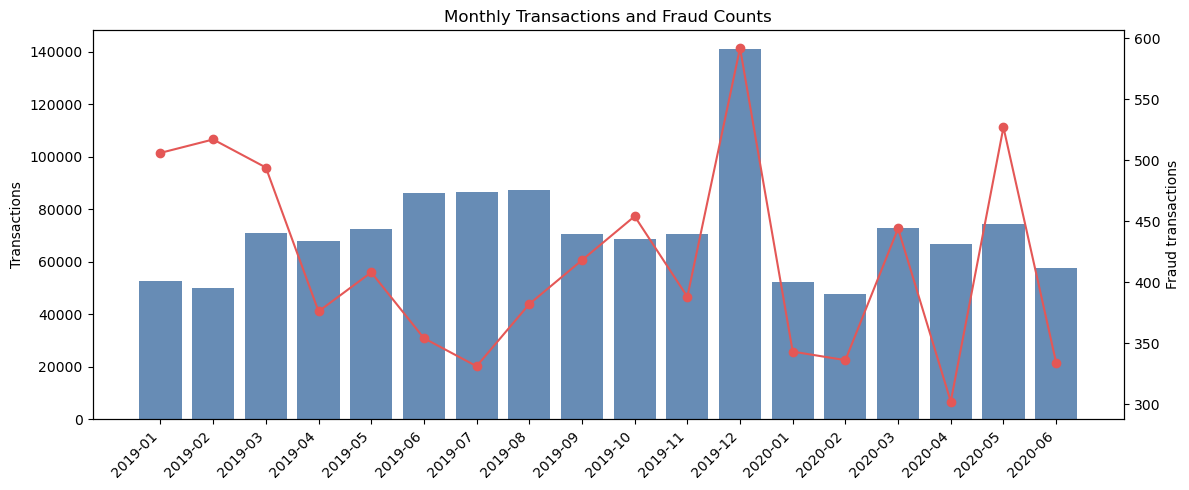

Monthly totals:


,transaction_count,fraud_count,amount_total
month,,,
2019-01,52525,506,3759750.03
2019-02,49866,517,3604662.23
2019-03,70939,494,5027886.40
2019-04,68078,376,4761504.58
2019-05,72532,408,5060903.32
2019-06,86064,354,6036397.42
2019-07,86596,331,6044026.74
2019-08,87359,382,6047288.65
2019-09,70652,418,4949834.42


In [6]:
#4. Transaction volume by Month

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

filename = "credit_card_transactions_clean.csv"
candidates = [
    Path("etl_output") / filename,
    Path("output") / filename,
    Path.home() / "Downloads" / filename,
]
DATA_PATH = next((path for path in candidates if path.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError("Clean CSV not found. Download it or run the ETL first.")

print(f"Reading: {DATA_PATH.resolve()}", flush=True)

monthly_parts = []
rows_read = 0

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=["transaction_datetime", "amount", "is_fraud"],
    chunksize=100_000,
):
    chunk["transaction_datetime"] = pd.to_datetime(
        chunk["transaction_datetime"], errors="coerce"
    )
    chunk["amount"] = pd.to_numeric(chunk["amount"], errors="coerce")
    chunk["is_fraud"] = pd.to_numeric(chunk["is_fraud"], errors="coerce")

    chunk = chunk.dropna(subset=["transaction_datetime"])
    chunk["month"] = chunk["transaction_datetime"].dt.to_period("M").astype(str)

    monthly_parts.append(
        chunk.groupby("month").agg(
            transaction_count=("is_fraud", "size"),
            fraud_count=("is_fraud", "sum"),
            amount_total=("amount", "sum"),
        )
    )

    rows_read += len(chunk)
    print(f"Processed {rows_read:,} rows...", flush=True)

by_month = pd.concat(monthly_parts).groupby(level=0).sum().sort_index()

fig, ax1 = plt.subplots(figsize=(12, 5))
x = range(len(by_month))
ax1.bar(x, by_month["transaction_count"], color="#4C78A8", alpha=0.85)
ax1.set_ylabel("Transactions")
ax1.set_xticks(list(x))
ax1.set_xticklabels(by_month.index, rotation=45, ha="right")
ax1.set_title("Monthly Transactions and Fraud Counts")

ax2 = ax1.twinx()
ax2.plot(x, by_month["fraud_count"], color="#E45756", marker="o")
ax2.set_ylabel("Fraud transactions")

fig.tight_layout()
plt.show()

print("Monthly totals:")
display(by_month)

Reading: C:\Users\jpmee\Downloads\credit_card_transactions_clean.csv
Processed 100,000 rows...
Processed 200,000 rows...
Processed 300,000 rows...
Processed 400,000 rows...
Processed 500,000 rows...
Processed 600,000 rows...
Processed 700,000 rows...
Processed 800,000 rows...
Processed 900,000 rows...
Processed 1,000,000 rows...
Processed 1,100,000 rows...
Processed 1,200,000 rows...
Processed 1,296,675 rows...


,transaction_count,fraud_count,fraud_rate,average_amount,fraud_rate_pct
category,,,,,
shopping_net,97543,1713,0.017561,88.424076,1.756149
misc_net,63287,915,0.014458,80.865095,1.445795
grocery_pos,123638,1743,0.014098,116.960986,1.409761
shopping_pos,116672,843,0.007225,79.779155,0.722538
gas_transport,131659,618,0.004694,63.434572,0.469394
misc_pos,79655,250,0.003139,62.890999,0.313853
grocery_net,45452,134,0.002948,53.670084,0.294817
travel,40507,116,0.002864,111.504720,0.286370
entertainment,94014,233,0.002478,64.210421,0.247835


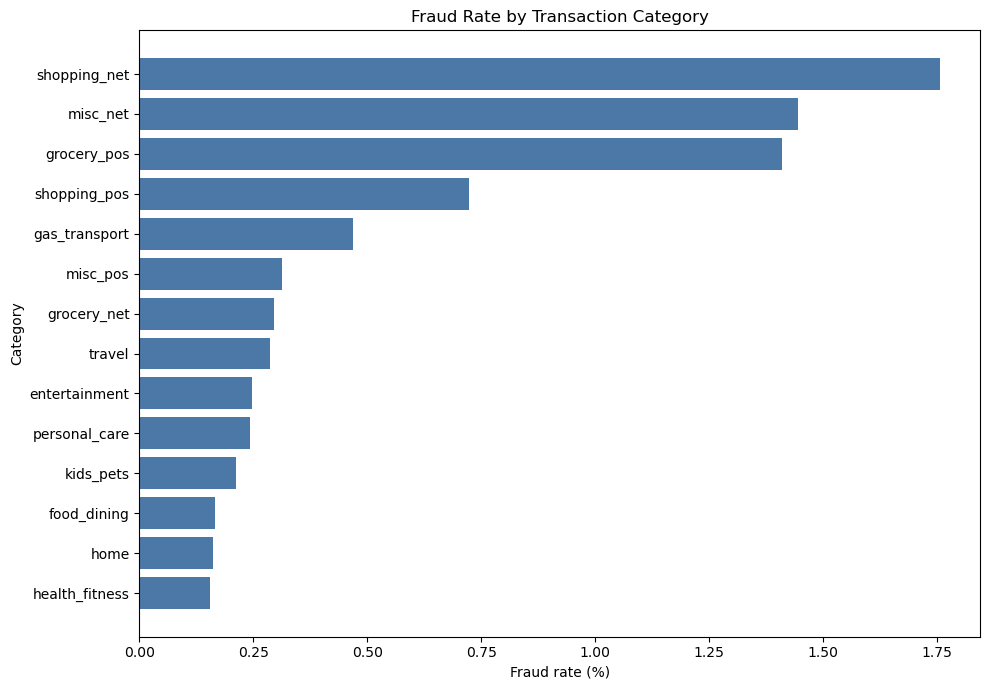

In [10]:
#5.Fraud Rate By Transaction Category

from pathlib import Path
import pandas as pd

filename = "credit_card_transactions_clean.csv"
candidates = [
    Path("etl_output") / filename,
    Path("output") / filename,
    Path.home() / "Downloads" / filename,
]
DATA_PATH = next((path for path in candidates if path.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError("Clean CSV not found. Download it or run the ETL first.")

category_parts = []
rows_read = 0

print(f"Reading: {DATA_PATH.resolve()}", flush=True)

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=["category", "amount", "is_fraud"],
    chunksize=100_000,
):
    chunk["amount"] = pd.to_numeric(chunk["amount"], errors="coerce")
    chunk["is_fraud"] = pd.to_numeric(chunk["is_fraud"], errors="coerce")

    category_parts.append(
        chunk.groupby("category").agg(
            transaction_count=("is_fraud", "size"),
            fraud_count=("is_fraud", "sum"),
            amount_total=("amount", "sum"),
        )
    )

    rows_read += len(chunk)
    print(f"Processed {rows_read:,} rows...", flush=True)

by_category = pd.concat(category_parts).groupby(level=0).sum()
by_category["fraud_rate"] = (
    by_category["fraud_count"] / by_category["transaction_count"]
)
by_category["average_amount"] = (
    by_category["amount_total"] / by_category["transaction_count"]
)

category_view = by_category[
    ["transaction_count", "fraud_count", "fraud_rate", "average_amount"]
].copy()
category_view["fraud_rate_pct"] = category_view["fraud_rate"] * 100
category_view = category_view.sort_values("fraud_rate", ascending=False)

display(category_view)
import matplotlib.pyplot as plt

plot_data = category_view.sort_values("fraud_rate_pct", ascending=True)

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(plot_data.index.astype(str), plot_data["fraud_rate_pct"], color="#4C78A8")

ax.set_title("Fraud Rate by Transaction Category")
ax.set_xlabel("Fraud rate (%)")
ax.set_ylabel("Category")
fig.tight_layout()
plt.show()


Reading: C:\Users\jpmee\Downloads\credit_card_transactions_clean.csv
Processed 100,000 rows...
Processed 200,000 rows...
Processed 300,000 rows...
Processed 400,000 rows...
Processed 500,000 rows...
Processed 600,000 rows...
Processed 700,000 rows...
Processed 800,000 rows...
Processed 900,000 rows...
Processed 1,000,000 rows...
Processed 1,100,000 rows...
Processed 1,200,000 rows...
Processed 1,296,675 rows...


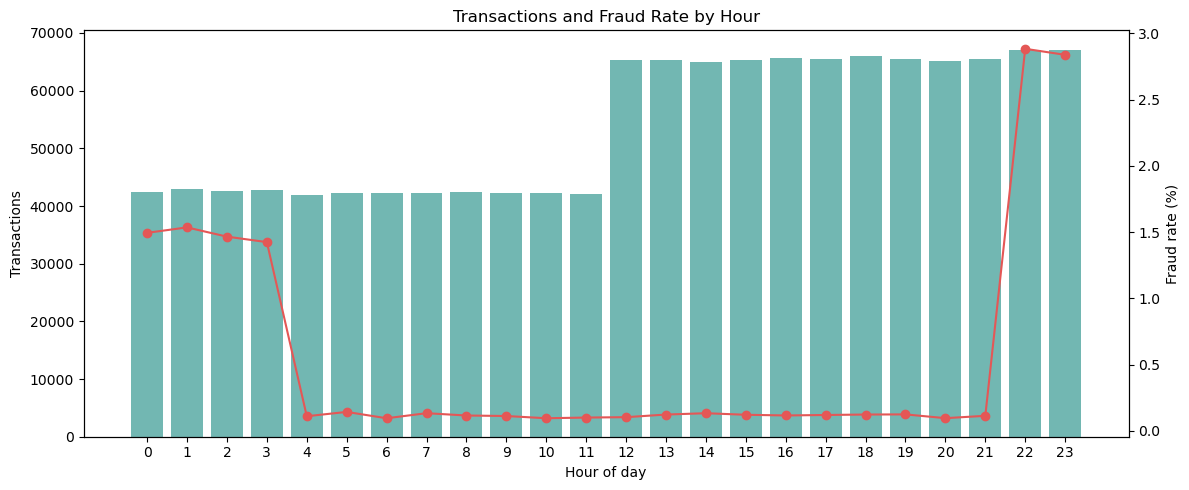

,transaction_count,fraud_count,fraud_rate_pct
hour,,,
0,42502,635,1.494047
1,42869,658,1.534909
2,42656,625,1.465210
3,42769,609,1.423929
4,41863,46,0.109882
5,42171,60,0.142278
6,42300,40,0.094563
7,42203,56,0.132692
8,42505,49,0.115281


In [14]:
# 6. Time-Of-Day-Pattern

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Find the clean CSV.
filename = "credit_card_transactions_clean.csv"
candidates = [
    Path("etl_output") / filename,
    Path("output") / filename,
    Path.home() / "Downloads" / filename,
]
DATA_PATH = next((path for path in candidates if path.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError("Clean CSV not found. Download it or run the ETL first.")

hour_parts = []
rows_read = 0
print(f"Reading: {DATA_PATH.resolve()}", flush=True)

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=["transaction_datetime", "is_fraud"],
    chunksize=100_000,
):
    chunk["transaction_datetime"] = pd.to_datetime(
        chunk["transaction_datetime"], errors="coerce"
    )
    chunk["is_fraud"] = pd.to_numeric(chunk["is_fraud"], errors="coerce")
    chunk = chunk.dropna(subset=["transaction_datetime", "is_fraud"])

    chunk["hour"] = chunk["transaction_datetime"].dt.hour

    hour_parts.append(
        chunk.groupby("hour").agg(
            transaction_count=("is_fraud", "size"),
            fraud_count=("is_fraud", "sum"),
        )
    )

    rows_read += len(chunk)
    print(f"Processed {rows_read:,} rows...", flush=True)

by_hour = pd.concat(hour_parts).groupby(level=0).sum().sort_index()
by_hour["fraud_rate_pct"] = (
    by_hour["fraud_count"] / by_hour["transaction_count"] * 100
)

hours = by_hour.index.astype(int)

fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.bar(hours, by_hour["transaction_count"], color="#72B7B2")
ax1.set_xlabel("Hour of day")
ax1.set_ylabel("Transactions")
ax1.set_xticks(range(24))
ax1.set_title("Transactions and Fraud Rate by Hour")

ax2 = ax1.twinx()
ax2.plot(hours, by_hour["fraud_rate_pct"], color="#E45756", marker="o")
ax2.set_ylabel("Fraud rate (%)")

fig.tight_layout()
plt.show()

display(by_hour)

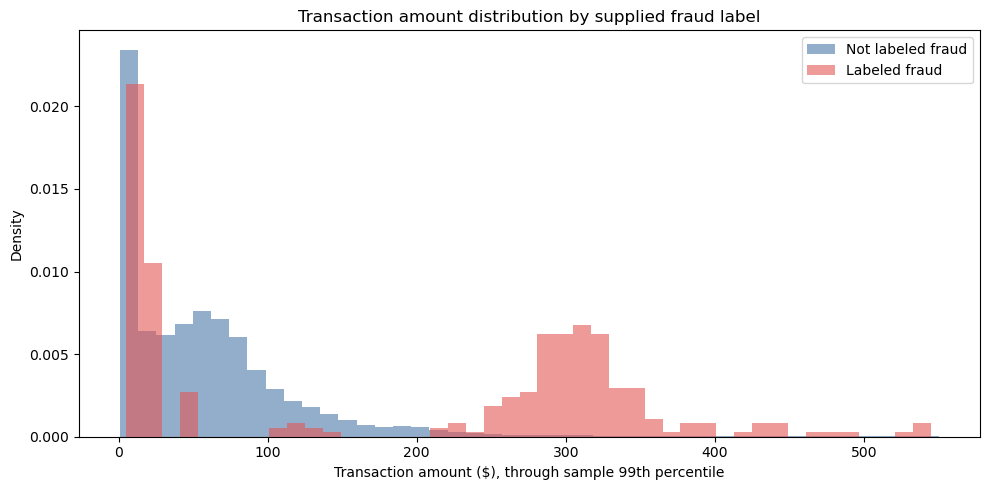

In [10]:
# 7. Amount Distribution

import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("credit_card_transactions.csv")

# Some transaction files call this column "amt"
if "amount" not in df.columns and "amt" in df.columns:
    df = df.rename(columns={"amt": "amount"})

sample = df.sample(n=min(100_000, len(df)), random_state=42)

amount_sample = sample.loc[
    sample["amount"].ge(0), ["amount", "is_fraud"]
].copy()

cap = amount_sample["amount"].quantile(0.99)
fig, ax = plt.subplots(figsize=(10, 5))

for label, color, name in [
    (0, "#4C78A8", "Not labeled fraud"),
    (1, "#E45756", "Labeled fraud"),
]:
    values = amount_sample.loc[
        (amount_sample["is_fraud"] == label)
        & (amount_sample["amount"] <= cap),
        "amount",
    ]
    ax.hist(values, bins=45, alpha=0.6, density=True, color=color, label=name)

ax.set_xlabel("Transaction amount ($), through sample 99th percentile")
ax.set_ylabel("Density")
ax.set_title("Transaction amount distribution by supplied fraud label")
ax.legend()
fig.tight_layout()
plt.show()

,transaction_count,fraud_count,average_amount,fraud_rate_pct
age_band,,,,
Under 20,34841,223,63.52,0.640
20–29,209265,1223,69.80,0.584
30–39,291264,1286,74.51,0.442
40–49,304356,1385,73.41,0.455
50–59,184927,1388,66.45,0.751
60–69,136515,855,65.51,0.626
70–79,72863,625,66.85,0.858
80+,62644,521,67.92,0.832


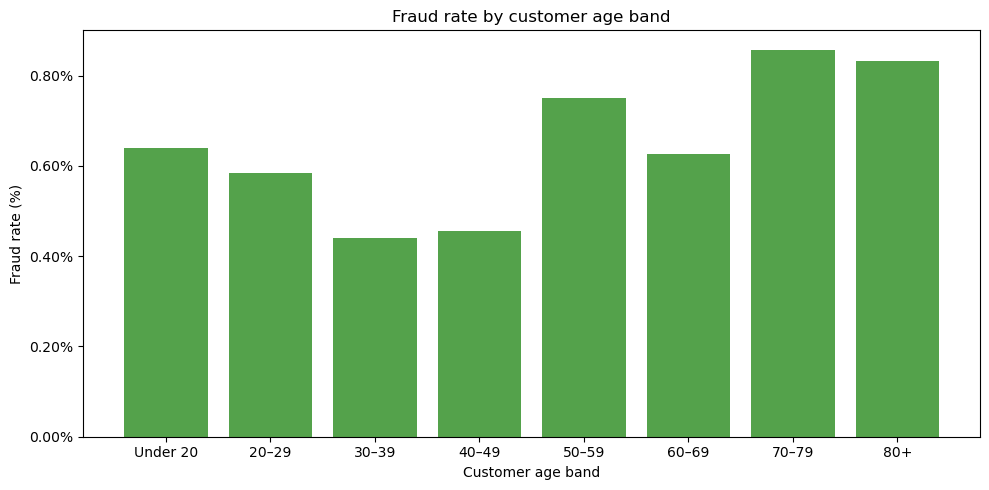

In [17]:
# 8. Custom Age Groups

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import display

# Use your loaded DataFrame
data = df.copy()

# Convert dates and calculate age at the time of each transaction
data["trans_date_trans_time"] = pd.to_datetime(
    data["trans_date_trans_time"], errors="coerce"
)
data["dob"] = pd.to_datetime(data["dob"], errors="coerce")

data["age"] = (
    (data["trans_date_trans_time"] - data["dob"]).dt.days / 365.25
)

# Create customer age bands
age_bins = [0, 20, 30, 40, 50, 60, 70, 80, 120]
age_labels = [
    "Under 20", "20–29", "30–39", "40–49",
    "50–59", "60–69", "70–79", "80+"
]

data["age_band"] = pd.cut(
    data["age"],
    bins=age_bins,
    labels=age_labels,
    right=False
)

# Support either the raw column name "amt" or the cleaned name "amount"
amount_col = "amount" if "amount" in data.columns else "amt"

# Create the age summary
by_age = (
    data.dropna(subset=["age_band", "is_fraud"])
    .groupby("age_band", observed=False)
    .agg(
        transaction_count=("is_fraud", "size"),
        fraud_count=("is_fraud", "sum"),
        fraud_rate=("is_fraud", "mean"),
        average_amount=(amount_col, "mean")
    )
)

# Remove age bands with no transactions
by_age = by_age[by_age["transaction_count"] > 0]

# Display the table
age_view = by_age[
    ["transaction_count", "fraud_count", "fraud_rate", "average_amount"]
].copy()

age_view["fraud_rate_pct"] = age_view["fraud_rate"] * 100

display(
    age_view.drop(columns="fraud_rate").round(
        {"average_amount": 2, "fraud_rate_pct": 3}
    )
)

# Plot fraud rate by age band
fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    age_view.index.astype(str),
    age_view["fraud_rate_pct"],
    color="#54A24B"
)

ax.set_xlabel("Customer age band")
ax.set_ylabel("Fraud rate (%)")
ax.set_title("Fraud rate by customer age band")
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda value, _: f"{value:.2f}%")
)

fig.tight_layout()
plt.show()

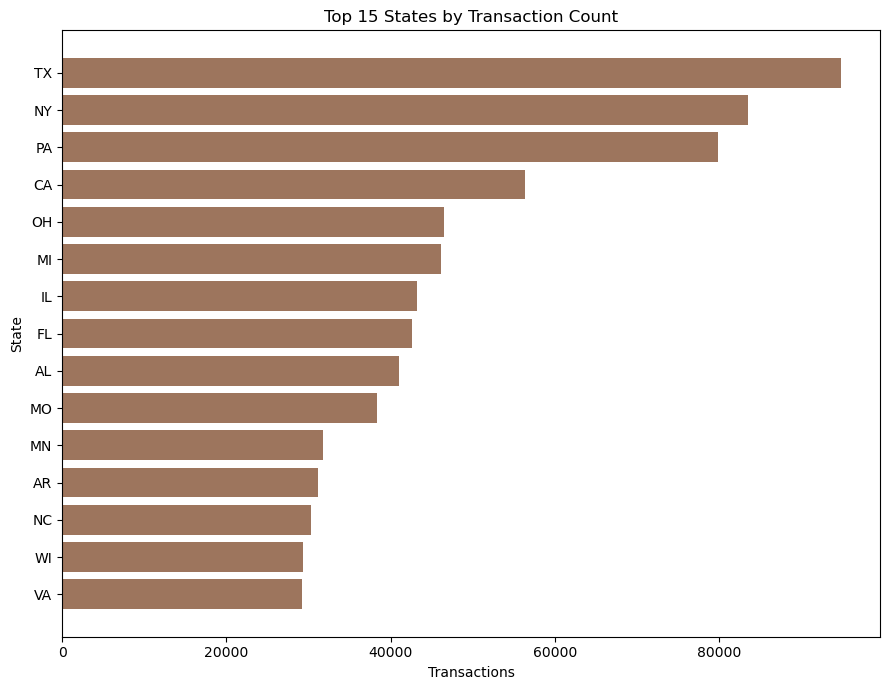

In [19]:
# 9. Geographic transaction volume

import matplotlib.pyplot as plt

# Count transactions for each state
by_state = (
    df.dropna(subset=["state"])
      .groupby("state")
      .size()
      .to_frame(name="transaction_count")
)

# Get the 15 states with the most transactions
top_states = (
    by_state.nlargest(15, "transaction_count")
            .sort_values("transaction_count")
)

# Create the chart
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(
    top_states.index.astype(str),
    top_states["transaction_count"],
    color="#9D755D"
)
ax.set_xlabel("Transactions")
ax.set_ylabel("State")
ax.set_title("Top 15 States by Transaction Count")
fig.tight_layout()
plt.show()

In [21]:
# 10. Data-driven Summary

import pandas as pd

# Use your loaded transaction DataFrame here.
# If it isn't named df, replace df with its actual name.
df["trans_date_trans_time"] = pd.to_datetime(
    df["trans_date_trans_time"], errors="coerce"
)
df["is_fraud"] = pd.to_numeric(df["is_fraud"], errors="coerce")
df = df.dropna(subset=["trans_date_trans_time", "is_fraud"]).copy()

df["month"] = df["trans_date_trans_time"].dt.to_period("M").astype(str)
df["hour"] = df["trans_date_trans_time"].dt.hour

by_month = df.groupby("month").agg(
    transaction_count=("is_fraud", "size")
)

by_category = df.groupby("category").agg(
    transaction_count=("is_fraud", "size"),
    fraud_count=("is_fraud", "sum")
)
by_category["fraud_rate"] = (
    by_category["fraud_count"] / by_category["transaction_count"]
)

by_hour = df.groupby("hour").agg(
    transaction_count=("is_fraud", "size"),
    fraud_count=("is_fraud", "sum")
)
by_hour["fraud_rate"] = (
    by_hour["fraud_count"] / by_hour["transaction_count"]
)

fraud_rate = df["is_fraud"].mean()

largest_month = by_month["transaction_count"].idxmax()
highest_category = by_category.loc[by_category["fraud_rate"].idxmax()]
highest_hour = by_hour["fraud_rate"].idxmax()

print(
    f"The largest transaction month is {largest_month} "
    f"({int(by_month.loc[largest_month, 'transaction_count']):,} records)."
)
print(
    f"The category with the highest observed fraud rate is "
    f"{by_category['fraud_rate'].idxmax()} "
    f"({highest_category['fraud_rate']:.2%}, "
    f"n={int(highest_category['transaction_count']):,})."
)
print(
    f"The hour with the highest observed fraud rate is {int(highest_hour):02d}:00 "
    f"({by_hour.loc[highest_hour, 'fraud_rate']:.2%}, "
    f"n={int(by_hour.loc[highest_hour, 'transaction_count']):,})."
)
print(f"Fraud labels account for {fraud_rate:.3%} of all records.")

The largest transaction month is 2019-12 (141,060 records).
The category with the highest observed fraud rate is shopping_net (1.76%, n=97,543).
The hour with the highest observed fraud rate is 22:00 (2.88%, n=66,982).
Fraud labels account for 0.579% of all records.


In [15]:
# 11 A. Compare segments over time and investigate high rates
from pathlib import Path
import pandas as pd

# Locate your credit card transactions CSV
folder = Path("C:/Users/jpmee/Downloads")

file_path = folder / "credit_card_transactions (1).csv"

# Check whether the file exists
if file_path.exists():
    print("SUCCESS: File found!")

    # Load the dataset
    df = pd.read_csv(file_path, low_memory=False)

    print("Total rows:", len(df))
    print("Total columns:", len(df.columns))

    print("\nColumn names:")
    print(df.columns.tolist())

    print("\nFirst 5 rows:")
    print(df.head())

else:
    print("ERROR: File not found.")
    print("Check this location:", file_path)


SUCCESS: File found!
Total rows: 1296675
Total columns: 24

Column names:
['Unnamed: 0', 'trans_date_trans_time', 'cc_num', 'merchant', 'category', 'amt', 'first', 'last', 'gender', 'street', 'city', 'state', 'zip', 'lat', 'long', 'city_pop', 'job', 'dob', 'trans_num', 'unix_time', 'merch_lat', 'merch_long', 'is_fraud', 'merch_zipcode']

First 5 rows:
   Unnamed: 0 trans_date_trans_time            cc_num  \
0           0   2019-01-01 00:00:18  2703186189652095   
1           1   2019-01-01 00:00:44      630423337322   
2           2   2019-01-01 00:00:51    38859492057661   
3           3   2019-01-01 00:01:16  3534093764340240   
4           4   2019-01-01 00:03:06   375534208663984   

                             merchant       category     amt      first  \
0          fraud_Rippin, Kub and Mann       misc_net    4.97   Jennifer   
1     fraud_Heller, Gutmann and Zieme    grocery_pos  107.23  Stephanie   
2                fraud_Lind-Buckridge  entertainment  220.11     Edward   
3  

In [17]:
# 11 A. Compare segments over time and investigate high rates continued

import pandas as pd
from pathlib import Path

# Set the location of your CSV file
DATA_PATH = Path(
    r"C:\Users\jpmee\Downloads\credit_card_transactions (1).csv"
)

# Check if the file exists
if DATA_PATH.exists():
    print("SUCCESS: File found!")

    # Load credit card transactions
    df = pd.read_csv(DATA_PATH, low_memory=False)

    # Display dataset information
    print("Total rows:", len(df))
    print("Total columns:", len(df.columns))

    print("\nColumn names:")
    print(df.columns.tolist())

    print("\nFirst 5 transactions:")
    display(df.head())

else:
    print("ERROR: File not found!")
    print("Location checked:", DATA_PATH)


SUCCESS: File found!
Total rows: 1296675
Total columns: 24

Column names:
['Unnamed: 0', 'trans_date_trans_time', 'cc_num', 'merchant', 'category', 'amt', 'first', 'last', 'gender', 'street', 'city', 'state', 'zip', 'lat', 'long', 'city_pop', 'job', 'dob', 'trans_num', 'unix_time', 'merch_lat', 'merch_long', 'is_fraud', 'merch_zipcode']

First 5 transactions:


,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,...,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud,merch_zipcode
0,0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,...,-81.1781,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0,28705.0
1,1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,...,-118.2105,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0,NaN
2,2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,...,-112.2620,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0,83236.0
3,3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,...,-112.1138,1939,Patent attorney,1967-01-12,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0,NaN
4,4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,...,-79.4629,99,Dance movement psychotherapist,1986-03-28,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0,22844.0


In [18]:
# 11 A. Analysis data completed

import pandas as pd
import matplotlib.pyplot as plt

# Load your dataset if it is not already loaded
if "df" not in globals():
    df = pd.read_csv(
        r"C:\Users\jpmee\Downloads\credit_card_transactions (1).csv",
        low_memory=False
    )

# Create a working copy
transactions = df.copy()

# Convert transaction dates
transactions["trans_date_trans_time"] = pd.to_datetime(
    transactions["trans_date_trans_time"],
    errors="coerce"
)

# Convert transaction amounts
transactions["amt"] = pd.to_numeric(
    transactions["amt"],
    errors="coerce"
)

# Remove records without valid dates or amounts
transactions = transactions.dropna(
    subset=["trans_date_trans_time", "amt"]
)

# Create month column
transactions["month"] = (
    transactions["trans_date_trans_time"]
    .dt.to_period("M")
)

print("SUCCESS: Data prepared for Step 11!")
print("Total valid transactions:", len(transactions))
print("First month:", transactions["month"].min())
print("Last month:", transactions["month"].max())

display(transactions[
    ["trans_date_trans_time", "month", "category", "amt"]
].head())


SUCCESS: Data prepared for Step 11!
Total valid transactions: 1296675
First month: 2019-01
Last month: 2020-06


,trans_date_trans_time,month,category,amt
0,2019-01-01 00:00:18,2019-01,misc_net,4.97
1,2019-01-01 00:00:44,2019-01,grocery_pos,107.23
2,2019-01-01 00:00:51,2019-01,entertainment,220.11
3,2019-01-01 00:01:16,2019-01,gas_transport,45.00
4,2019-01-01 00:03:06,2019-01,misc_pos,41.96


In [19]:

11 B # Group transactions by month

monthly_summary = (
    transactions.groupby("month")
    .agg(
        transaction_count=("amt", "size"),
        total_spending=("amt", "sum"),
        average_transaction=("amt", "mean")
    )
    .reset_index()
)

# Calculate month-over-month percentage changes
monthly_summary["transaction_growth_pct"] = (
    monthly_summary["transaction_count"]
    .pct_change() * 100
)

monthly_summary["spending_growth_pct"] = (
    monthly_summary["total_spending"]
    .pct_change() * 100
)

# Format month labels
monthly_summary["month"] = (
    monthly_summary["month"].astype(str)
)

print("MONTH-TO-MONTH TRANSACTION COMPARISON")
display(monthly_summary.round(2))


MONTH-TO-MONTH TRANSACTION COMPARISON


,month,transaction_count,total_spending,average_transaction,transaction_growth_pct,spending_growth_pct
0,2019-01,52525,3759750.03,71.58,NaN,NaN
1,2019-02,49866,3604662.23,72.29,-5.06,-4.12
2,2019-03,70939,5027886.40,70.88,42.26,39.48
3,2019-04,68078,4761504.58,69.94,-4.03,-5.30
4,2019-05,72532,5060903.32,69.77,6.54,6.29
5,2019-06,86064,6036397.42,70.14,18.66,19.28
6,2019-07,86596,6044026.74,69.80,0.62,0.13
7,2019-08,87359,6047288.65,69.22,0.88,0.05
8,2019-09,70652,4949834.42,70.06,-19.12,-18.15
9,2019-10,68758,4851267.37,70.56,-2.68,-1.99


In [20]:

# 11 C. Compare monthly spending across categories
category_monthly = (
    transactions.groupby(["month", "category"])["amt"]
    .sum()
    .unstack(fill_value=0)
)

# Select the 5 highest-spending categories
top_categories = (
    transactions.groupby("category")["amt"]
    .sum()
    .nlargest(5)
    .index
)

category_comparison = category_monthly[top_categories]

print("TOP 5 SPENDING CATEGORIES BY MONTH")
display(category_comparison.round(2))


TOP 5 SPENDING CATEGORIES BY MONTH


category,grocery_pos,shopping_pos,shopping_net,gas_transport,home
month,,,,,
2019-01,583681.06,388868.18,399951.86,334646.51,296041.31
2019-02,573807.44,361595.08,391268.41,326042.26,273428.57
2019-03,798714.86,502572.09,466924.14,448118.02,392909.11
2019-04,763146.23,449794.92,424088.00,444723.97,369711.07
2019-05,826642.57,523586.29,510366.49,461301.72,402503.46
2019-06,954065.14,645411.81,518334.23,562467.86,473952.10
2019-07,956660.89,568226.35,568998.21,561287.54,474869.71
2019-08,954957.01,587820.76,558211.46,565371.33,472697.82
2019-09,755374.74,517754.90,464746.78,451263.92,390554.88


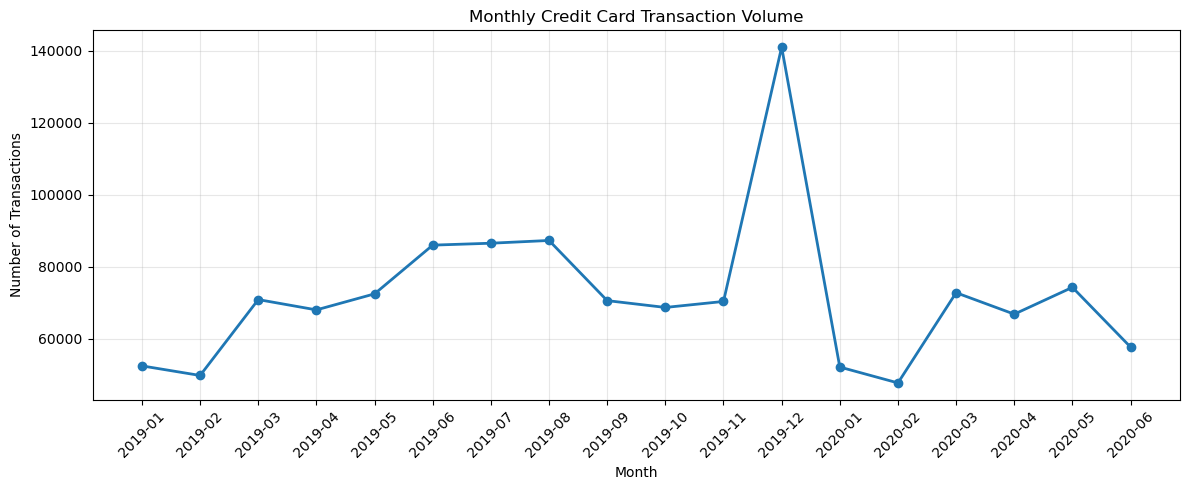

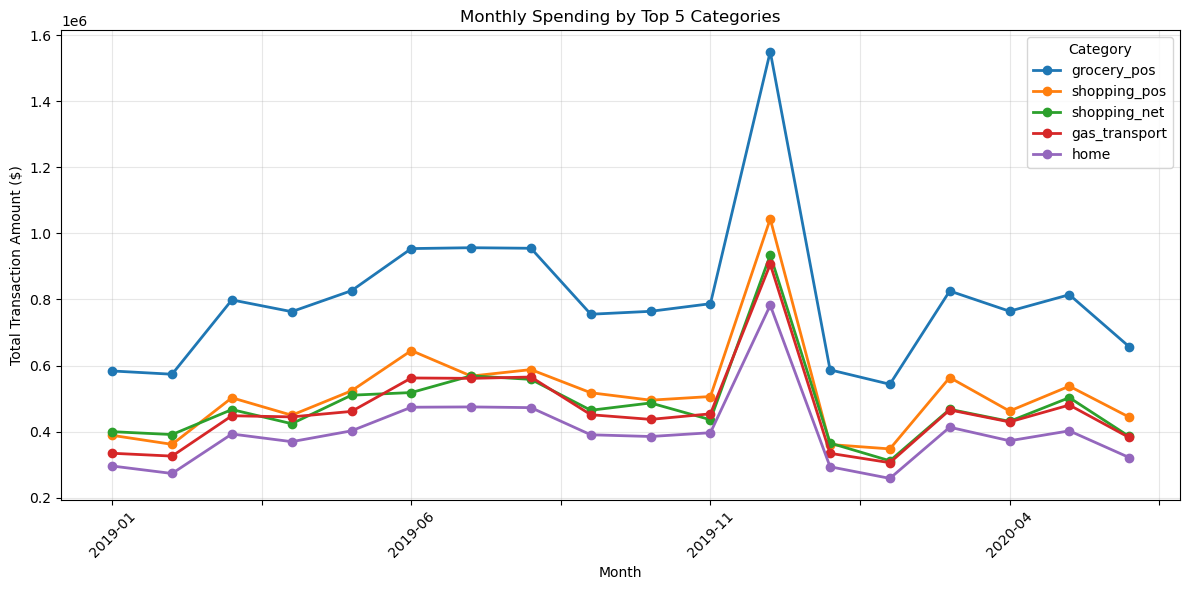

SUCCESS: Step 11 graphs generated!


In [21]:
#11 Analysis 11 Completed

# Graph 1: Monthly transaction counts
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    monthly_summary["month"],
    monthly_summary["transaction_count"],
    marker="o",
    linewidth=2
)

ax.set_title("Monthly Credit Card Transaction Volume")
ax.set_xlabel("Month")
ax.set_ylabel("Number of Transactions")
ax.tick_params(axis="x", rotation=45)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Graph 2: Monthly spending by category
fig, ax = plt.subplots(figsize=(12, 6))

category_comparison.index = (
    category_comparison.index.astype(str)
)

category_comparison.plot(
    ax=ax,
    marker="o",
    linewidth=2
)

ax.set_title("Monthly Spending by Top 5 Categories")
ax.set_xlabel("Month")
ax.set_ylabel("Total Transaction Amount ($)")
ax.tick_params(axis="x", rotation=45)
ax.legend(title="Category")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("SUCCESS: Step 11 graphs generated!")


In [22]:

from pathlib import Path

output_folder = Path(
    r"C:\Users\jpmee\Downloads\credit_card_analysis"
)

output_folder.mkdir(parents=True, exist_ok=True)

monthly_summary.to_csv(
    output_folder / "monthly_summary.csv",
    index=False
)

category_comparison.to_csv(
    output_folder / "category_monthly_comparison.csv"
)

print("SUCCESS: Step 11 analysis saved!")
print("Output folder:", output_folder)


SUCCESS: Step 11 analysis saved!
Output folder: C:\Users\jpmee\Downloads\credit_card_analysis


MONTH-TO-MONTH TRANSACTION COMPARISON


,month,transaction_count,total_spending,average_transaction,transaction_growth_pct,spending_growth_pct
0,2019-01,52525,3759750.03,71.58,NaN,NaN
1,2019-02,49866,3604662.23,72.29,-5.06,-4.12
2,2019-03,70939,5027886.40,70.88,42.26,39.48
3,2019-04,68078,4761504.58,69.94,-4.03,-5.30
4,2019-05,72532,5060903.32,69.77,6.54,6.29
5,2019-06,86064,6036397.42,70.14,18.66,19.28
6,2019-07,86596,6044026.74,69.80,0.62,0.13
7,2019-08,87359,6047288.65,69.22,0.88,0.05
8,2019-09,70652,4949834.42,70.06,-19.12,-18.15
9,2019-10,68758,4851267.37,70.56,-2.68,-1.99



========== KEY FINDINGS ==========
Highest Transaction Volume: 141,060 (2019-12)
Highest Monthly Spending: $9,918,179.18 (2019-12)
Largest Monthly Growth: +100.31% (2019-12)
Largest Monthly Decline: -62.99% (2020-01)


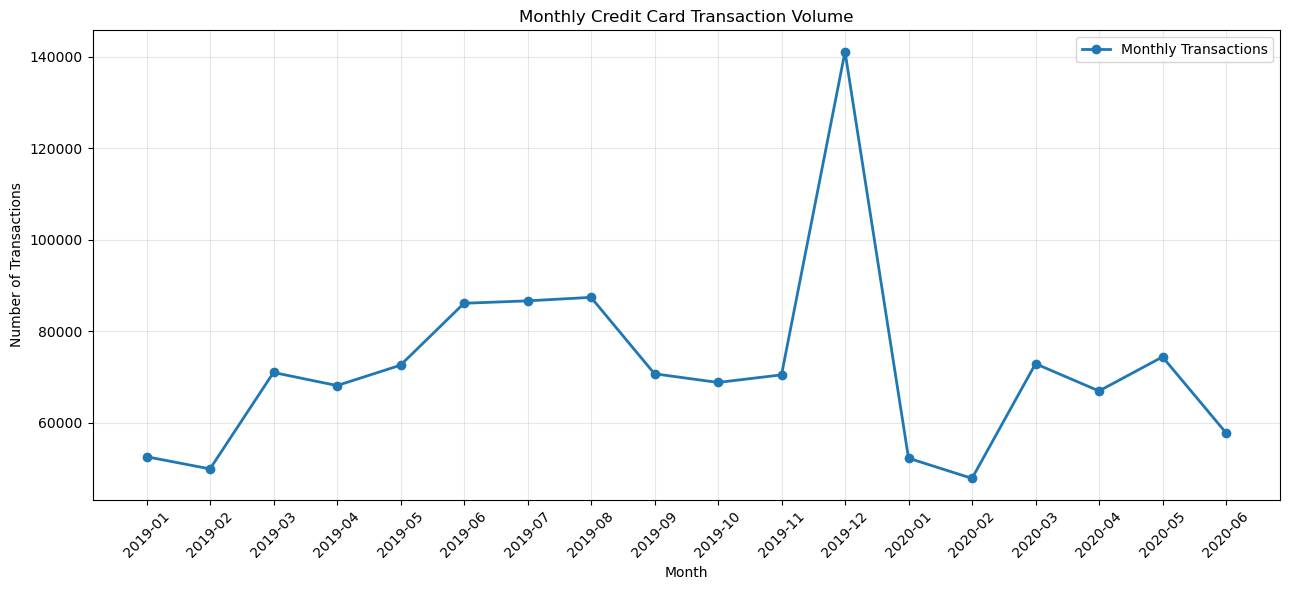


SUCCESS: Step 11B analysis completed!


In [24]:
#11B.Analysis 11B completed

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

# STEP 1: Load credit card transactions
file_path = Path(
    r"C:\Users\jpmee\Downloads\credit_card_transactions (1).csv"
)

df = pd.read_csv(file_path, low_memory=False)

# STEP 2: Prepare data
df["trans_date_trans_time"] = pd.to_datetime(
    df["trans_date_trans_time"],
    errors="coerce"
)

df["amt"] = pd.to_numeric(df["amt"], errors="coerce")

df = df.dropna(
    subset=["trans_date_trans_time", "amt"]
)

df["month"] = df["trans_date_trans_time"].dt.to_period("M")

# STEP 3: Monthly transaction summary
monthly_summary = (
    df.groupby("month")
    .agg(
        transaction_count=("amt", "size"),
        total_spending=("amt", "sum"),
        average_transaction=("amt", "mean")
    )
    .reset_index()
    .sort_values("month")
)

# STEP 4: Calculate monthly growth
monthly_summary["transaction_growth_pct"] = (
    monthly_summary["transaction_count"].pct_change() * 100
)

monthly_summary["spending_growth_pct"] = (
    monthly_summary["total_spending"].pct_change() * 100
)

monthly_summary["month"] = monthly_summary["month"].astype(str)

# STEP 5: Display monthly summary
print("MONTH-TO-MONTH TRANSACTION COMPARISON")
display(monthly_summary.round(2))

# STEP 6: Identify key findings
highest_volume = monthly_summary.loc[
    monthly_summary["transaction_count"].idxmax()
]

highest_spending = monthly_summary.loc[
    monthly_summary["total_spending"].idxmax()
]

largest_growth = monthly_summary.loc[
    monthly_summary["transaction_growth_pct"].idxmax()
]

largest_decline = monthly_summary.loc[
    monthly_summary["transaction_growth_pct"].idxmin()
]

print("\n========== KEY FINDINGS ==========")

print(
    f"Highest Transaction Volume: "
    f"{highest_volume['transaction_count']:,.0f} "
    f"({highest_volume['month']})"
)

print(
    f"Highest Monthly Spending: "
    f"${highest_spending['total_spending']:,.2f} "
    f"({highest_spending['month']})"
)

print(
    f"Largest Monthly Growth: "
    f"{largest_growth['transaction_growth_pct']:+.2f}% "
    f"({largest_growth['month']})"
)

print(
    f"Largest Monthly Decline: "
    f"{largest_decline['transaction_growth_pct']:+.2f}% "
    f"({largest_decline['month']})"
)

# STEP 7: Create transaction volume graph
fig, ax = plt.subplots(figsize=(13, 6))

ax.plot(
    monthly_summary["month"],
    monthly_summary["transaction_count"],
    marker="o",
    linewidth=2,
    label="Monthly Transactions"
)

ax.set_title("Monthly Credit Card Transaction Volume")
ax.set_xlabel("Month")
ax.set_ylabel("Number of Transactions")
ax.tick_params(axis="x", rotation=45)
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

print("\nSUCCESS: Step 11B analysis completed!")


TOP 5 CREDIT CARD SPENDING CATEGORIES


category,gas_transport,grocery_pos,home,shopping_net,shopping_pos
month,,,,,
2019-01,334646.51,583681.06,296041.31,399951.86,388868.18
2019-02,326042.26,573807.44,273428.57,391268.41,361595.08
2019-03,448118.02,798714.86,392909.11,466924.14,502572.09
2019-04,444723.97,763146.23,369711.07,424088.00,449794.92
2019-05,461301.72,826642.57,402503.46,510366.49,523586.29
2019-06,562467.86,954065.14,473952.10,518334.23,645411.81
2019-07,561287.54,956660.89,474869.71,568998.21,568226.35
2019-08,565371.33,954957.01,472697.82,558211.46,587820.76
2019-09,451263.92,755374.74,390554.88,464746.78,517754.90


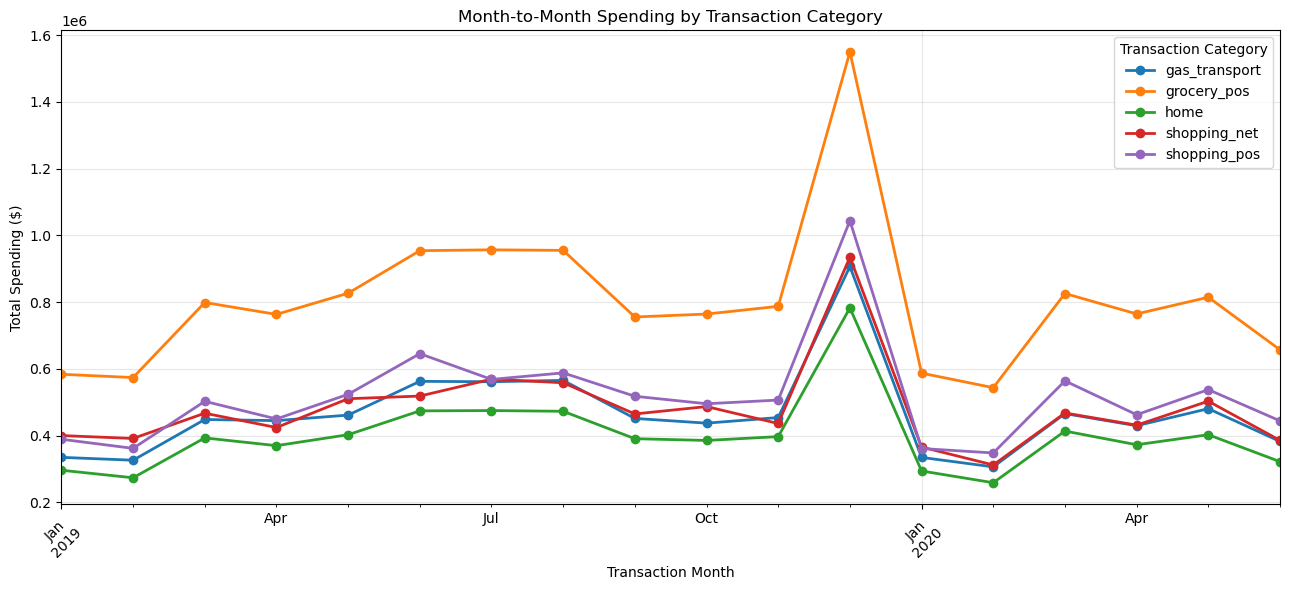

SUCCESS: Category segment analysis completed!


In [25]:

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Use the transactions dataset from Step 11B
# Identify the five highest-spending categories
top_categories = (
    transactions.groupby("category")["amt"]
    .sum()
    .nlargest(5)
    .index
)

# Calculate monthly spending by category
category_monthly = (
    transactions[
        transactions["category"].isin(top_categories)
    ]
    .groupby(["month", "category"])["amt"]
    .sum()
    .unstack(fill_value=0)
    .sort_index()
)

print("TOP 5 CREDIT CARD SPENDING CATEGORIES")
display(category_monthly.round(2))

# Create monthly spending comparison graph
fig, ax = plt.subplots(figsize=(13, 6))

category_monthly.plot(
    ax=ax,
    marker="o",
    linewidth=2
)

ax.set_title(
    "Month-to-Month Spending by Transaction Category"
)
ax.set_xlabel("Transaction Month")
ax.set_ylabel("Total Spending ($)")
ax.grid(alpha=0.3)

ax.tick_params(axis="x", rotation=45)
ax.legend(title="Transaction Category")

plt.tight_layout()
plt.show()

print("SUCCESS: Category segment analysis completed!")


In [27]:
#12.Use monthly summer from Step 11B.

import pandas as pd

# Use the monthly_summary table from Step 11B
required = [
    "month",
    "transaction_count",
    "total_spending",
    "average_transaction",
    "transaction_growth_pct",
    "spending_growth_pct"
]

missing = [col for col in required if col not in monthly_summary.columns]

if missing:
    print("Missing columns:", missing)
    print("Run Step 11B first.")

else:
    results = monthly_summary.copy()
    results["month"] = results["month"].astype(str)
    results = results.set_index("month")

    print("=" * 65)
    print("STEP 11B: BUSINESS INTERPRETATIONS")
    print("=" * 65)

    # December 2019
    if "2019-12" in results.index:
        dec = results.loc["2019-12"]

        print("\n1. DECEMBER 2019: TRANSACTION GROWTH")
        print(
            f"Transaction volume increased "
            f"{dec['transaction_growth_pct']:.2f}% "
            f"compared with November 2019."
        )
        print(
            f"Total spending reached "
            f"${dec['total_spending']:,.2f}."
        )
        print(
            "Business Interpretation: The substantial increase "
            "may reflect holiday shopping or other seasonal "
            "activity. Additional analysis is needed to "
            "confirm the cause."
        )

    # January 2020
    if "2020-01" in results.index:
        jan = results.loc["2020-01"]

        print("\n2. JANUARY 2020: TRANSACTION DECLINE")
        print(
            f"Transaction volume changed "
            f"{jan['transaction_growth_pct']:+.2f}% "
            f"compared with December 2019."
        )
        print(
            f"Total spending changed "
            f"{jan['spending_growth_pct']:+.2f}%."
        )
        print(
            "Business Interpretation: Transaction activity "
            "declined sharply following December's peak. "
            "This may indicate a return to normal spending "
            "levels after the holiday period."
        )

    # March 2020
    if "2020-03" in results.index:
        mar = results.loc["2020-03"]

        print("\n3. MARCH 2020: TRANSACTION RECOVERY")
        print(
            f"Transaction volume increased "
            f"{mar['transaction_growth_pct']:.2f}% "
            f"compared with February 2020."
        )
        print(
            f"Total spending increased "
            f"{mar['spending_growth_pct']:.2f}%."
        )
        print(
            "Business Interpretation: March experienced "
            "a substantial increase in transaction activity. "
            "Category-level analysis can help identify "
            "which spending segments contributed."
        )

    # Average transaction amount
    avg_min = results["average_transaction"].min()
    avg_max = results["average_transaction"].max()

    print("\n4. AVERAGE TRANSACTION AMOUNT")
    print(
        f"Monthly average transaction values ranged "
        f"from ${avg_min:.2f} to ${avg_max:.2f}."
    )
    print(
        "Business Interpretation: Average transaction "
        "amounts remained relatively stable. Changes "
        "in total spending were primarily associated "
        "with changes in transaction volume."
    )

    print("\n" + "=" * 65)
    print("SUCCESS: BUSINESS INTERPRETATIONS COMPLETED")
    print("=" * 65)


STEP 11B: BUSINESS INTERPRETATIONS

1. DECEMBER 2019: TRANSACTION GROWTH
Transaction volume increased 100.31% compared with November 2019.
Total spending reached $9,918,179.18.
Business Interpretation: The substantial increase may reflect holiday shopping or other seasonal activity. Additional analysis is needed to confirm the cause.

2. JANUARY 2020: TRANSACTION DECLINE
Transaction volume changed -62.99% compared with December 2019.
Total spending changed -63.07%.
Business Interpretation: Transaction activity declined sharply following December's peak. This may indicate a return to normal spending levels after the holiday period.

3. MARCH 2020: TRANSACTION RECOVERY
Transaction volume increased 52.43% compared with February 2020.
Total spending increased 53.18%.
Business Interpretation: March experienced a substantial increase in transaction activity. Category-level analysis can help identify which spending segments contributed.

4. AVERAGE TRANSACTION AMOUNT
Monthly average transacti

In [28]:
#13 A. Baseline Model On a Chronological Holdout

from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score, confusion_matrix

# Find the latest uploaded raw CSV. Update this list if your file is elsewhere.
_raw_candidates = [
    Path("upload/credit_card_transactions(3).csv"),
    Path("credit_card_transactions(3).csv"),
    Path("../upload/credit_card_transactions(3).csv"),
    Path("../credit_card_transactions(3).csv"),
    Path("upload/credit_card_transactions(2).csv"),
    Path("credit_card_transactions(2).csv"),
    Path("upload/credit_card_transactions(1).csv"),
    Path("credit_card_transactions(1).csv"),
    Path("upload/credit_card_transactions.csv"),
    Path("credit_card_transactions.csv"),
]
RAW_DATA_PATH = next((p for p in _raw_candidates if p.exists()), None)
if RAW_DATA_PATH is None:
    raise FileNotFoundError(
        "Raw CSV not found. Place credit_card_transactions(3).csv next to the "
        "notebook or in its upload/ folder, or update _raw_candidates."
    )

CHUNK_SIZE = 150_000
print(f"Using raw CSV: {RAW_DATA_PATH.resolve()}", flush=True)
print("Scanning transaction dates for the chronological cutoff...", flush=True)

# Set the final 90 days aside as a chronological test period.
max_dt = None
for chunk_number, chunk in enumerate(
    pd.read_csv(
        RAW_DATA_PATH,
        usecols=["trans_date_trans_time"],
        chunksize=CHUNK_SIZE,
        low_memory=False,
    ),
    start=1,
):
    dates = pd.to_datetime(chunk["trans_date_trans_time"], errors="coerce")
    chunk_max = dates.max()
    if pd.notna(chunk_max):
        max_dt = chunk_max if max_dt is None else max(max_dt, chunk_max)
    print(f"  Scanned date chunk {chunk_number:,}", flush=True)

if max_dt is None:
    raise ValueError("No valid transaction dates were found in the CSV.")

cutoff = max_dt.normalize() - pd.Timedelta(days=90)
print(f"Holdout starts {cutoff:%Y-%m-%d}; latest date is {max_dt:%Y-%m-%d}.", flush=True)

feature_cols = ["amt", "category", "trans_date_trans_time", "is_fraud"]
rng = np.random.default_rng(2026)
train_parts = []
test_parts = []
n_train = n_test = 0

print("Preparing training sample and holdout rows...", flush=True)
for chunk_number, chunk in enumerate(
    pd.read_csv(
        RAW_DATA_PATH,
        usecols=feature_cols,
        chunksize=CHUNK_SIZE,
        low_memory=False,
    ),
    start=1,
):
    chunk["trans_date_trans_time"] = pd.to_datetime(
        chunk["trans_date_trans_time"], errors="coerce"
    )
    chunk["amt"] = pd.to_numeric(chunk["amt"], errors="coerce")
    chunk["is_fraud"] = pd.to_numeric(chunk["is_fraud"], errors="coerce")
    chunk = chunk.dropna(
        subset=["trans_date_trans_time", "amt", "category", "is_fraud"]
    )
    chunk = chunk.loc[chunk["is_fraud"].isin([0, 1])].copy()
    if chunk.empty:
        continue

    chunk["is_fraud"] = chunk["is_fraud"].astype("int8")
    dates = chunk["trans_date_trans_time"]
    train_chunk = chunk.loc[dates < cutoff].copy()
    test_chunk = chunk.loc[dates >= cutoff].copy()
    n_train += len(train_chunk)
    n_test += len(test_chunk)

    if len(train_chunk):
        keep = rng.random(len(train_chunk)) < 0.20
        if keep.any():
            train_parts.append(train_chunk.loc[keep])
    if len(test_chunk):
        test_parts.append(test_chunk)

    print(
        f"  Prepared chunk {chunk_number:,}; "
        f"training population {n_train:,}, holdout {n_test:,}",
        flush=True,
    )

if not train_parts or not test_parts:
    raise ValueError("The file did not produce both training and test rows.")

train = pd.concat(train_parts, ignore_index=True)
test = pd.concat(test_parts, ignore_index=True)

def make_features(frame):
    dates = frame["trans_date_trans_time"]
    features = pd.DataFrame(index=frame.index)
    features["log_amount"] = np.log1p(frame["amt"].clip(lower=0))
    features["hour"] = dates.dt.hour.astype("int8")
    features["day_of_week"] = dates.dt.dayofweek.astype("int8")
    features["category"] = frame["category"].astype("string").fillna("Unknown")
    return features

X_train = make_features(train)
y_train = train["is_fraud"].to_numpy()
X_test = make_features(test)
y_test = test["is_fraud"].to_numpy()

if len(np.unique(y_train)) < 2 or len(np.unique(y_test)) < 2:
    raise ValueError("Training and test data must each contain both label classes.")

preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), ["log_amount", "hour", "day_of_week"]),
    ("category", OneHotEncoder(handle_unknown="ignore"), ["category"]),
])

model = make_pipeline(
    preprocessor,
    LogisticRegression(
        class_weight="balanced",
        max_iter=300,
        solver="liblinear",
        random_state=2026,
    ),
)

print(
    f"Fitting model on {len(train):,} sampled training rows; "
    f"evaluating on {len(test):,} holdout rows...",
    flush=True,
)
model.fit(X_train, y_train)

print("Scoring holdout and calculating metrics...", flush=True)
probabilities = model.predict_proba(X_test)[:, 1]
average_precision = average_precision_score(y_test, probabilities)
roc_auc = roc_auc_score(y_test, probabilities)
baseline_rate = y_test.mean()

# Example review capacity: inspect the highest-scoring 1% of holdout rows.
review_count = max(1, int(np.ceil(0.01 * len(y_test))))
top_indices = np.argpartition(probabilities, -review_count)[-review_count:]
top_recall = (
    float(y_test[top_indices].sum() / y_test.sum())
    if y_test.sum()
    else 0.0
)
top_precision = float(y_test[top_indices].mean())

# 0.50 threshold is shown for illustration, not as an operational recommendation.
predictions = probabilities >= 0.50
matrix = confusion_matrix(y_test, predictions, labels=[0, 1])

print(f"Holdout begins: {cutoff:%Y-%m-%d}; ends: {max_dt:%Y-%m-%d}")
print(
    f"Training population: {n_train:,}; 20% sample used for fitting: {len(train):,}; "
    f"positive labels in sample: {int(y_train.sum()):,}"
)
print(
    f"Test population: {n_test:,}; test fraud labels: {int(y_test.sum()):,}; "
    f"test prevalence: {baseline_rate * 100:.3f}%"
)
print(
    f"Logistic Regression | Average precision: {average_precision:.4f} "
    f"({average_precision * 100:.3f}%) | ROC AUC: {roc_auc:.4f}"
)
print(
    f"Top 1% review example: {review_count:,} transactions | "
    f"precision: {top_precision * 100:.2f}% | "
    f"fraud-label recall: {top_recall * 100:.2f}%"
)
print("Confusion matrix at probability threshold 0.50 [rows=true 0/1, columns=predicted 0/1]:")
print(matrix)
print(
    "Note: exploratory baseline only; the 0.50 threshold and top-1% capacity "
    "are examples, not operational recommendations."
)


Using raw CSV: C:\Users\jpmee\credit_card_transactions.csv
Scanning transaction dates for the chronological cutoff...
  Scanned date chunk 1
  Scanned date chunk 2
  Scanned date chunk 3
  Scanned date chunk 4
  Scanned date chunk 5
  Scanned date chunk 6
  Scanned date chunk 7
  Scanned date chunk 8
  Scanned date chunk 9
Holdout starts 2020-03-23; latest date is 2020-06-21.
Preparing training sample and holdout rows...
  Prepared chunk 1; training population 150,000, holdout 0
  Prepared chunk 2; training population 300,000, holdout 0
  Prepared chunk 3; training population 450,000, holdout 0
  Prepared chunk 4; training population 600,000, holdout 0
  Prepared chunk 5; training population 750,000, holdout 0
  Prepared chunk 6; training population 900,000, holdout 0
  Prepared chunk 7; training population 1,050,000, holdout 0
  Prepared chunk 8; training population 1,075,553, holdout 124,447
  Prepared chunk 9; training population 1,075,553, holdout 221,122
Fitting model on 215,689 s

In [29]:
#13 B. Baseline Readout

import pandas as pd
from IPython.display import display

# Use your cleaned credit card transaction DataFrame
# Change df if your DataFrame has a different name
data = df.copy()

# Convert transaction amount to numeric
data["amt"] = pd.to_numeric(data["amt"], errors="coerce")

# Remove missing transaction amounts
data = data.dropna(subset=["amt"])

# Calculate baseline metrics
baseline = pd.DataFrame({
    "Metric": [
        "Total Transactions",
        "Total Transaction Amount",
        "Average Transaction Amount",
        "Median Transaction Amount",
        "Minimum Transaction Amount",
        "Maximum Transaction Amount"
    ],
    "Value": [
        len(data),
        data["amt"].sum(),
        data["amt"].mean(),
        data["amt"].median(),
        data["amt"].min(),
        data["amt"].max()
    ]
})

baseline["Value"] = baseline["Value"].round(2)

print("STEP 11A: BASELINE TRANSACTION READOUT")
display(baseline)


STEP 11A: BASELINE TRANSACTION READOUT


,Metric,Value
0,Total Transactions,1296675.00
1,Total Transaction Amount,91222428.90
2,Average Transaction Amount,70.35
3,Median Transaction Amount,47.52
4,Minimum Transaction Amount,1.00
5,Maximum Transaction Amount,28948.90


In [30]:
#13 C. Baseline Intrepretation 

total = len(data)
spending = data["amt"].sum()
average = data["amt"].mean()
median = data["amt"].median()

print("STEP 11B: BUSINESS INTERPRETATION")
print("-" * 55)

print(f"1. The dataset contains {total:,} transactions.")

print(
    f"2. Total transaction spending reached "
    f"${spending:,.2f}."
)

print(
    f"3. The average transaction amount was "
    f"${average:,.2f}."
)

print(
    f"4. The median transaction amount was "
    f"${median:,.2f}."
)

if average > median:
    print(
        "5. The average exceeds the median, suggesting "
        "larger purchases may be influencing spending."
    )
else:
    print(
        "5. The average does not exceed the median, "
        "suggesting large purchases are not pulling "
        "the average above the typical transaction."
    )

print(
    "6. These metrics establish a baseline for "
    "comparing monthly transaction performance."
)


STEP 11B: BUSINESS INTERPRETATION
-------------------------------------------------------
1. The dataset contains 1,296,675 transactions.
2. Total transaction spending reached $91,222,428.90.
3. The average transaction amount was $70.35.
4. The median transaction amount was $47.52.
5. The average exceeds the median, suggesting larger purchases may be influencing spending.
6. These metrics establish a baseline for comparing monthly transaction performance.
